# Лабораторная работа №1

## Цели и задачи

Научиться строить эмпирическую функцию распределения, изучить
скорость ее сходимости к генеральной функции распределения; построить гистограмму и
заклеймить ее позором.

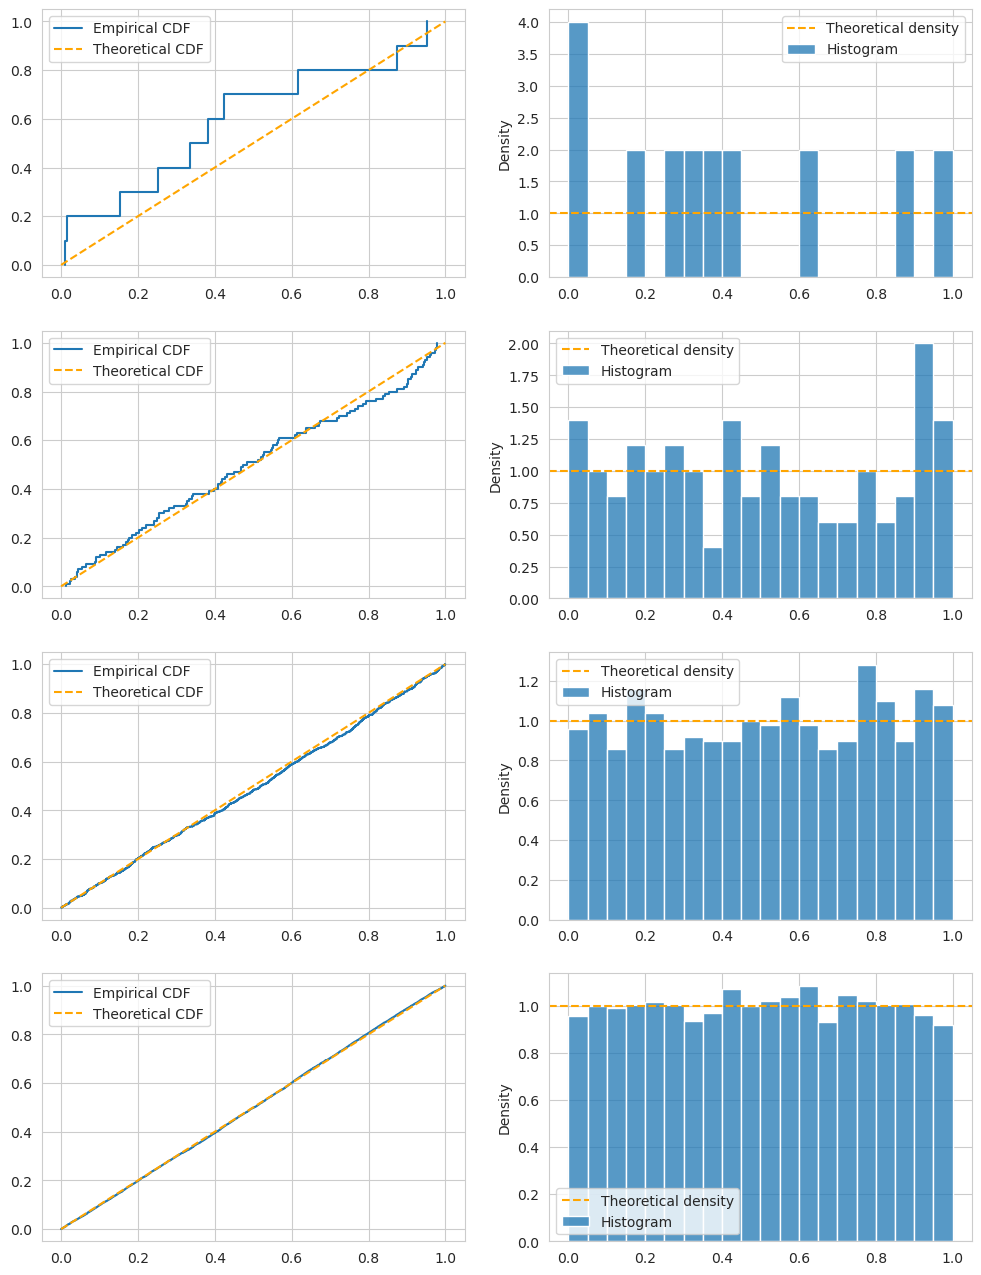

In [1]:
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt

sns.set_style("whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
errors = []
for i in range(4):
    size = 10**(i+1)
    x = np.sort(np.random.uniform(size=size))
    ecdf = [sum(x <= x_i)/len(x) for x_i in x]
    axes[i][0].step(np.r_[x[0], x], np.r_[0, ecdf], where='post', label='Empirical CDF')
    errors.append(np.max(ecdf - x))
    axes[i][0].legend()
    sns.lineplot(data=[0,1], ax=axes[i][0], label='Theoretical CDF', color='orange', linestyle='--')
    sns.histplot(data=x, ax=axes[i][1], bins=20, stat='density', label='Histogram', binrange=(0,1))
    axes[i][1].axhline(1, color='orange', linestyle='--', label='Theoretical density')
    axes[i][1].legend()

In [2]:
for i, error in enumerate(errors):
    print(f"n: {10**(i+1)}\t\tmax error: {error}")

n: 10		max error: 0.2762800789838987
n: 100		max error: 0.0440091513299769
n: 1000		max error: 0.009053209061797296
n: 10000		max error: 0.007592338106935048


## Вывод

Исходя из полученных данных, полученных путём генерации и вычислений, можно сделать следующие выводы:
1. C ростом количества элементов в выборке эмпирическая функция распределения стремится к теоретической функции распределения. При этом для пар $n=100$ и $n=10000$ выполнилось условие, что с увеличением объёма выборки в $k=100$ раз, ошибка уменьшилась примерно в $\sqrt k = 10$ раз.
2. С ростом количества элементов в выборке нормализованния по площади гистограмма стремится к теоретической плотности распределения.